# Assignment 2 — Mass Analyzers

> **AI-use disclosure:** OpenAI Codex assisted with organizing and reviewing this notebook and with writing and revising the code, equations, calculations, plots, and explanations using the supplied lecture material. This included solving for the extraction delay that equalizes the two Problem 2 arrival times. All code cells were run from a fresh kernel to check the calculations. The author is responsible for reviewing the work and following the course AI-use policy.

Run the notebook from top to bottom. Cell 1.1 imports the libraries used throughout. Each code cell has a markdown heading numbered by problem and step.

## Problem 1 — Design a dual-sector mass spectrometer

**Prompt:** Use an acceleration voltage around 8 kV and a magnetic field around 1 T. Choose a radius between 10 cm and 1 m for each sector and a reasonable electric-sector plate gap (about 1 cm). Calculate the transmitted *m/z* at 1 T, the required electric-sector voltage, and the magnetic-field sweep for 100–1,000 *m/z*. Explain why a high *m/z* range is difficult to achieve.

### 1.1 — Design choices and constants

Choose $V_a=8{,}000$ V, magnetic radius $r_B=0.50$ m, electric radius $r_E=0.25$ m, and plate gap $d=0.010$ m. Both radii are within the requested range.

Assume positive ions with charge $q=ze$, negligible initial kinetic energy relative to $qV_a$, nonrelativistic motion, and velocity perpendicular to a uniform magnetic field. Use the lecture's narrow-gap approximation $E\approx V_{\mathrm{sector}}/d$ for the curved electric plates. These calculations specify the central trajectories; sector angles, slits, and the detailed focusing geometry would also be needed to build an instrument.

**Sources:** *Mass Analyzer Equations*, pp. 1–2; *Ion Motion Class Notes*, pp. 2–3; and *Ion Motion and Mass Analyzers* handout, Section 2 (pp. 1–2). Constants and calculations use SI units; the final *m/z* values are in Da per elementary charge.

In [24]:
# Shared imports for all three problems.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.constants import elementary_charge, atomic_mass, Boltzmann, torr
from scipy.optimize import brentq
from IPython.display import display

e = elementary_charge  # C
u = atomic_mass        # kg per Da
V_acc = 8000.0         # V: acceleration voltage
B_reference = 1.0      # T
r_B = 0.50             # m: magnetic-sector radius
r_E = 0.25             # m: electric-sector radius
plate_gap = 0.010      # m

design = pd.DataFrame({
    'Parameter': ['Acceleration voltage', 'Reference magnetic field',
                  'Magnetic-sector radius', 'Electric-sector radius', 'Plate gap'],
    'Value': [V_acc, B_reference, r_B, r_E, plate_gap],
    'Unit': ['V', 'T', 'm', 'm', 'm'],
})
display(design.style.hide(axis='index').format({'Value': '{:g}'}))

Parameter,Value,Unit
Acceleration voltage,8000,V
Reference magnetic field,1,T
Magnetic-sector radius,0.5,m
Electric-sector radius,0.25,m
Plate gap,0.01,m


### 1.2 — Transmitted m/z at 1 T

The acceleration energy and magnetic force balance are

$$\frac{1}{2}mv^2=zeV_a, \qquad \frac{mv^2}{r_B}=zevB.$$

Combining them gives the lecture equation

$$\frac{m}{z}=\frac{eB^2r_B^2}{2V_a}.$$

With SI inputs, this gives $m/z$ in **kg per charge number**. Divide by $u$, the mass of 1 Da in kg, to obtain the numerical *m/z* in Da per elementary charge:

$$\mu\equiv (m/z)_{\mathrm{Da}/e}=\frac{eB^2r_B^2}{2V_a u}.$$

Here $z$ is the integer charge number, not charge in coulombs. The calculated value is the ion's mass-to-charge ratio; it is not a neutral-mass estimate.

In [25]:
def mz_from_field(B_T):
    # Return numerical m/z in Da per elementary charge.
    return e * np.asarray(B_T)**2 * r_B**2 / (2 * V_acc * u)

mz_reference = float(mz_from_field(B_reference))
print(f'Transmitted m/z at {B_reference:.2f} T: {mz_reference:,.2f} Da/e')

# Independently check both force and energy equations using a +1 ion.
ion_mass_kg = mz_reference * u
ion_speed = np.sqrt(2 * e * V_acc / ion_mass_kg)
radius_check = ion_mass_kg * ion_speed / (e * B_reference)
assert np.isclose(radius_check, r_B)
print(f'Calculated magnetic radius from energy and force: {radius_check:.3f} m')

Transmitted m/z at 1.00 T: 1,507.58 Da/e
Calculated magnetic radius from energy and force: 0.500 m


### 1.3 — Electric-sector voltage

Use the same acceleration energy in the electric force balance:

$$\frac{mv^2}{r_E}=zeE, \qquad mv^2=2zeV_a.$$

Therefore

$$E=\frac{2V_a}{r_E}, \qquad V_{\mathrm{sector}}\approx Ed=\frac{2V_a d}{r_E}.$$

$V_{\mathrm{sector}}$ is the **potential difference between the plates**, distinct from the 8 kV acceleration voltage. The field must point toward the center of curvature for positive ions, so the inner plate is at a lower potential than the outer plate. For this narrow gap, the uniform-field approximation is appropriate. At fixed acceleration voltage, the electric sector selects kinetic energy per charge and its setting is independent of *m/z*.

In [26]:
E_sector = 2 * V_acc / r_E
V_sector = E_sector * plate_gap
print(f'Electric-sector field: {E_sector:,.0f} V/m')
print(f'Required plate-to-plate voltage: {V_sector:,.0f} V')
print(f'Example plate potentials: inner {-V_sector/2:.0f} V, outer +{V_sector/2:.0f} V')

assert np.isclose(2 * plate_gap * V_acc / V_sector, r_E)

Electric-sector field: 64,000 V/m
Required plate-to-plate voltage: 640 V
Example plate potentials: inner -320 V, outer +320 V


### 1.4 — Magnetic-field sweep from 100 to 1,000 m/z

Keep the acceleration voltage, both radii, and electric-sector voltage fixed. Rearranging the magnetic-sector equation gives

$$B(\mu)=\sqrt{\frac{2V_a u\mu}{e r_B^2}}.$$

Increasing *m/z* requires increasing $B$. A tenfold increase in *m/z* requires a field increase by $\sqrt{10}$, rather than by ten. For equally spaced *m/z* values, program a square-root field sweep. If *m/z* is scanned linearly in time over a chosen duration $T$, then

$$\mu(t)=100+900\frac{t}{T}, \qquad B(t)=\sqrt{\frac{2V_a u}{e r_B^2}\left(100+900\frac{t}{T}\right)}, \quad 0\leq t\leq T.$$

A linear field ramp would instead produce a quadratic *m/z* scan. No scan duration is specified in the problem.

m/z (Da/e),Magnetic field (T)
100,0.2575
200,0.3642
300,0.4461
400,0.5151
500,0.5759
600,0.6309
700,0.6814
800,0.7285
900,0.7726
"1,000",0.8144


Sweep B from 0.2575 to 0.8144 T.
Field ratio: 3.1623; sqrt(10) = 3.1623
Keep acceleration at 8,000 V and the sector voltage at 640 V.


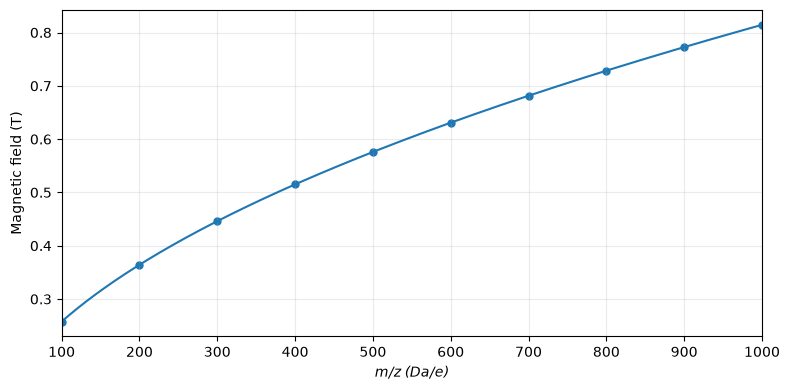

In [27]:
def field_from_mz(mz_Da_per_e):
    return np.sqrt(2 * V_acc * u * np.asarray(mz_Da_per_e) / (e * r_B**2))

mz_points = np.arange(100.0, 1001.0, 100.0)
B_points = field_from_mz(mz_points)
scan_table = pd.DataFrame({'m/z (Da/e)': mz_points, 'Magnetic field (T)': B_points})
display(scan_table.style.hide(axis='index').format({
    'm/z (Da/e)': '{:,.0f}', 'Magnetic field (T)': '{:.4f}',
}))
print(f'Sweep B from {B_points[0]:.4f} to {B_points[-1]:.4f} T.')
print(f'Field ratio: {B_points[-1] / B_points[0]:.4f}; sqrt(10) = {np.sqrt(10):.4f}')
print(f'Keep acceleration at {V_acc:,.0f} V and the sector voltage at {V_sector:,.0f} V.')

# Verify that every programmed field transmits the requested m/z.
assert np.allclose(mz_from_field(B_points), mz_points)
assert np.all(np.diff(B_points) > 0)
assert B_points[-1] < B_reference

mz_curve = np.linspace(100, 1000, 400)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mz_curve, field_from_mz(mz_curve), label='Square-root field sweep')
ax.scatter(mz_points, B_points, s=25)
ax.set_xlabel('m/z (Da/e)', fontstyle='italic')
ax.set_ylabel('Magnetic field (T)')
ax.set_xlim(100, 1000)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

### Why is a high m/z range difficult?

At fixed acceleration voltage, the transmitted mass-to-charge ratio scales as $\mu\propto B^2r_B^2$. High *m/z* therefore requires a stronger magnetic field, a larger magnetic-sector radius, or a lower acceleration voltage.

For this design, 1 T transmits about **1,508 m/z**. Reaching **10,000 m/z** at 8 kV would require about **2.58 T** with the same 50 cm radius, or a radius of about **1.29 m** at 1 T. Stronger fields make a large-gap analyzing magnet more demanding: conventional iron magnets face magnetic saturation, and higher fields may require more costly magnet technology. Increasing the radius makes the magnet, vacuum chamber, and instrument larger and heavier.

Lowering the acceleration voltage would extend the mass range at fixed field and radius, but reduces kinetic energy per charge. For a given initial energy spread, that increases the relative energy spread and makes high-resolution focusing more demanding. A dual-sector instrument also needs an electric sector and accurately aligned ion optics, adding size and construction complexity. The electric sector corrects energy dispersion when used in a suitable focusing geometry; it does not remove the magnetic sector's $B r_B$ requirement. Its ideal radius is independent of *m/z*, so the main mass-range constraint here is the magnetic sector.

**Problem 1 answers:** With $V_a=8$ kV, $r_B=50$ cm, $r_E=25$ cm, and a 1 cm plate gap, the design transmits **1,507.58 m/z at 1 T**, requires **640 V between the electric-sector plates**, and scans 100–1,000 *m/z* by increasing $B$ from **0.2575 to 0.8144 T** while keeping both voltages fixed.

The construction discussion follows from the lecture scaling equations; it is a qualitative engineering explanation, not a detailed magnet or double-focusing optical design.

### 1.5 — TA answer checker

Enter the student's design in the `student_design` dictionary below, then run this cell. **Radii and gap are in centimeters; acceleration voltage is in kilovolts.** Run cell 1.1 once first to load the shared imports.

The checker reports the expected m/z, electric-sector field and plate-to-plate voltage, and magnetic-field endpoints for the requested scan. It uses the same lecture equations as Sections 1.2–1.4. A radius outside the assignment's 10–100 cm range is flagged while its answers are still calculated. The written explanation of the high-m/z limitation should be graded separately.

In [28]:
# EDIT THESE VALUES to match the student's design.
student_design = {
    'magnetic_radius_cm': 50.0,
    'electric_radius_cm': 25.0,
    'plate_gap_cm': 1.0,
    'acceleration_kV': 8.0,
    'reference_field_T': 1.0,
    'scan_min_mz': 100.0,
    'scan_max_mz': 1000.0,
}


def problem1_answers(magnetic_radius_cm, electric_radius_cm, plate_gap_cm,
                     acceleration_kV=8.0, reference_field_T=1.0,
                     scan_min_mz=100.0, scan_max_mz=1000.0):
    """Calculate expected answers from the student's design, using lecture equations."""
    inputs = np.array([
        magnetic_radius_cm, electric_radius_cm, plate_gap_cm,
        acceleration_kV, reference_field_T, scan_min_mz, scan_max_mz,
    ], dtype=float)
    if not np.all(np.isfinite(inputs)) or np.any(inputs <= 0):
        raise ValueError('All inputs must be finite, positive numbers.')
    if scan_min_mz >= scan_max_mz:
        raise ValueError('The lower scan m/z must be below the upper scan m/z.')

    # Convert the editable inputs to SI units.
    magnetic_radius = magnetic_radius_cm / 100
    electric_radius = electric_radius_cm / 100
    gap = plate_gap_cm / 100
    acceleration_V = acceleration_kV * 1000

    mz = elementary_charge * reference_field_T**2 * magnetic_radius**2 / (
        2 * acceleration_V * atomic_mass
    )
    electric_field = 2 * acceleration_V / electric_radius
    sector_voltage = electric_field * gap
    scan_fields = np.sqrt(
        2 * acceleration_V * atomic_mass * np.array([scan_min_mz, scan_max_mz])
        / (elementary_charge * magnetic_radius**2)
    )
    return {
        'm/z (Da/e)': mz,
        'Electric-sector field (V/m)': electric_field,
        'Plate-to-plate sector voltage (V)': sector_voltage,
        'Scan start field (T)': scan_fields[0],
        'Scan end field (T)': scan_fields[1],
    }


checker_answers = problem1_answers(**student_design)
print(f"Expected m/z is evaluated at {student_design['reference_field_T']:g} T.")
print(f"Scan: {student_design['scan_min_mz']:g} to {student_design['scan_max_mz']:g} m/z.")
display(pd.DataFrame(
    checker_answers.items(), columns=['Expected answer', 'Value']
).style.hide(axis='index').format({'Value': '{:,.6f}'}))

for key, label in [('magnetic_radius_cm', 'Magnetic radius'),
                   ('electric_radius_cm', 'Electric radius')]:
    radius = student_design[key]
    status = 'within the required range' if 10 <= radius <= 100 else 'OUTSIDE the required range'
    print(f'{label}: {radius:g} cm — {status} (10–100 cm).')


Expected m/z is evaluated at 1 T.
Scan: 100 to 1000 m/z.


Expected answer,Value
m/z (Da/e),"1,507.583313"
Electric-sector field (V/m),"64,000.000000"
Plate-to-plate sector voltage (V),640.000000
Scan start field (T),0.257549
Scan end field (T),0.814440


Magnetic radius: 50 cm — within the required range (10–100 cm).
Electric radius: 25 cm — within the required range (10–100 cm).


## Problem 2 — MALDI-ToF and delayed extraction

**Prompt:** Study a 148 kDa antibody in a MALDI-ToF instrument with a 1 m drift tube and 2 kV acceleration. Calculate the ion velocity and arrival time. For a 1 cm acceleration region and initial velocities of 100 and 200 m/s, calculate velocities and arrival times with no delay and with 200 ns delayed extraction. Adjust controllable settings to make the arrival-time difference zero without changing the geometry or ion properties.

### 2.1 — Baseline velocity and drift time

Assume a **+1 charge state** ($q=e$), as in the lecture MALDI example, and use 148,000 Da as the ion mass. The drift tube is **1 m after** the 1 cm acceleration region. Both ions start at the same position, $x=0$, at the laser pulse and move toward the detector along the tube. Ignore collisions, space charge, and extraction-pulse rise time.

For an ion initially at rest, the lecture equations give

$$\frac12mv^2=eV_a,\qquad v=\sqrt{\frac{2eV_a}{m}},\qquad t_{\mathrm{drift}}=\frac{L}{v}.$$

The usual ToF estimate $L/v$ excludes time in the acceleration region. Below, **arrival time** means time from the laser pulse to the detector and includes the delay, acceleration time, and drift time. We report the drift-only time separately so these conventions are explicit.

**Sources:** *Mass Analyzer Equations*, pp. 1–3; *IonMotionHandout*, p. 1 (delayed-extraction exercise); and *Ion Motion Class Notes*, pp. 4–5. The position-dependent energy and finite acceleration time below follow from constant-acceleration kinematics applied to these lecture equations.

In [29]:
tof_mass = 148000.0 * u          # kg; fixed ion mass
tof_charge = e                  # C; fixed +1 charge state
tof_voltage = 2000.0            # V; fixed acceleration voltage
tof_gap = 0.010                 # m; acceleration region
tof_length = 1.0                # m; drift tube after acceleration
tof_initial_speeds = np.array([100.0, 200.0])  # m/s

tof_acceleration = tof_charge * tof_voltage / (tof_mass * tof_gap)
tof_rest_speed = np.sqrt(2 * tof_charge * tof_voltage / tof_mass)
tof_rest_drift = tof_length / tof_rest_speed
tof_rest_accel_time = 2 * tof_gap / tof_rest_speed

print(f'Ion mass: {tof_mass:.6e} kg')
print(f'Velocity from rest: {tof_rest_speed:.3f} m/s')
print(f'Drift-only time: {tof_rest_drift * 1e6:.6f} µs')
print(f'Acceleration time: {tof_rest_accel_time * 1e6:.6f} µs')
print(f'Arrival from laser pulse: {(tof_rest_accel_time + tof_rest_drift) * 1e6:.6f} µs')

Ion mass: 2.457598e-22 kg
Velocity from rest: 1614.841 m/s
Drift-only time: 619.255987 µs
Acceleration time: 12.385120 µs
Arrival from laser pulse: 631.641107 µs


### 2.2 — Finite acceleration region with no delay

During an extraction delay $\delta$, the field is off and an ion coasts to $x_0=v_0\delta$. When the fixed 2 kV voltage is switched on, assume a uniform field across the same 1 cm region:

$$E=\frac{V_a}{d},\qquad a=\frac{qV_a}{md},\qquad s=d-v_0\delta.$$

The ion travels the remaining distance $s$ under acceleration, so

$$v_f=\sqrt{v_0^2+2as}
=\sqrt{v_0^2+\frac{2qV_a}{m}\left(1-\frac{v_0\delta}{d}\right)},$$

$$t_{\mathrm{acc}}=\frac{v_f-v_0}{a}=\frac{2s}{v_f+v_0},\qquad
t_{\mathrm{drift}}=\frac{L}{v_f},\qquad
t_{\mathrm{arrival}}=\delta+t_{\mathrm{acc}}+t_{\mathrm{drift}}.$$

The second form for $t_{\mathrm{acc}}$ avoids subtracting similar velocities. The model requires $0\leq v_0\delta<d$ so extraction occurs before the ions leave the acceleration region.

**No delayed extraction:** set $\delta=0$. Both ions receive the full $qV_a$ energy, in addition to their initial kinetic energy. The faster initial ion remains faster and reaches the detector first.

In [30]:
def tof_trajectory(initial_speed, delay_s):
    """Return final speed and acceleration, drift, and total times in SI units."""
    initial_speed = np.asarray(initial_speed, dtype=float)
    if delay_s < 0 or np.any(initial_speed < 0):
        raise ValueError('Delay and initial speeds must be nonnegative.')

    remaining = tof_gap - initial_speed * delay_s
    if np.any(remaining <= 0):
        raise ValueError('Extraction must occur before either ion leaves the gap.')

    final_speed = np.sqrt(initial_speed**2 + 2 * tof_acceleration * remaining)
    accel_time = 2 * remaining / (final_speed + initial_speed)
    drift_time = tof_length / final_speed
    arrival_time = delay_s + accel_time + drift_time
    return final_speed, accel_time, drift_time, arrival_time


def tof_table(delay_s):
    speed, accel, drift, arrival = tof_trajectory(tof_initial_speeds, delay_s)
    return pd.DataFrame({
        'Ion': ['Ion 1 (100 m/s)', 'Ion 2 (200 m/s)'],
        'Final velocity (m/s)': speed,
        'Acceleration time (µs)': accel * 1e6,
        'Drift time (µs)': drift * 1e6,
        'Arrival from laser (µs)': arrival * 1e6,
    })


def show_tof_table(frame):
    formats = {column: '{:.6f}' for column in frame.columns if column != 'Ion'}
    formats['Final velocity (m/s)'] = '{:,.3f}'
    display(frame.style.hide(axis='index').format(formats))
    arrival_1, arrival_2 = frame['Arrival from laser (µs)']
    difference = f'{arrival_1 - arrival_2:.6f}'.replace('-0.000000', '0.000000')
    print(f'Arrival difference (Ion 1 - Ion 2): {difference} µs')


tof_no_delay = tof_table(0.0)
show_tof_table(tof_no_delay)

# Check the full-energy limit and the initially stationary baseline.
assert np.allclose(
    tof_no_delay['Final velocity (m/s)'].to_numpy()**2,
    tof_initial_speeds**2 + 2 * tof_charge * tof_voltage / tof_mass,
    rtol=1e-12, atol=0.0,
)
assert np.isclose(tof_trajectory(0.0, 0.0)[0], tof_rest_speed, rtol=1e-12, atol=0.0)

Ion,Final velocity (m/s),Acceleration time (µs),Drift time (µs),Arrival from laser (µs)
Ion 1 (100 m/s),"1,617.934",11.641888,618.072036,629.713924
Ion 2 (200 m/s),"1,627.179",10.945835,614.560516,625.506351


Arrival difference (Ion 1 - Ion 2): 4.207573 µs


### 2.3 — Apply 200 ns delayed extraction

With $\delta=200$ ns, Ion 1 moves **20 micrometers** and Ion 2 moves **40 micrometers** before the field is switched on. The faster ion is closer to the exit, so it experiences a smaller remaining voltage drop and receives less acceleration energy. Use the same 2 kV voltage, 1 cm gap, 1 m drift tube, mass, charge, and initial velocities as above. Include the common 200 ns delay in both arrival times.

In [31]:
tof_delay_200ns = 200e-9
tof_200ns = tof_table(tof_delay_200ns)
show_tof_table(tof_200ns)
print('Positions at extraction (µm):', tof_initial_speeds * tof_delay_200ns * 1e6)

# Check the energy gained over the remaining potential drop.
tof_200ns_speeds = tof_200ns['Final velocity (m/s)'].to_numpy()
remaining_voltage = tof_voltage * (1 - tof_initial_speeds * tof_delay_200ns / tof_gap)
assert np.allclose(
    0.5 * tof_mass * (tof_200ns_speeds**2 - tof_initial_speeds**2),
    tof_charge * remaining_voltage, rtol=1e-12, atol=0.0,
)

Ion,Final velocity (m/s),Acceleration time (µs),Drift time (µs),Arrival from laser (µs)
Ion 1 (100 m/s),"1,616.322",11.629521,618.688669,630.518189
Ion 2 (200 m/s),"1,623.971",10.921228,615.774657,626.895885


Arrival difference (Ion 1 - Ion 2): 3.622304 µs
Positions at extraction (µm): [20. 40.]


### 2.4 — Solve for zero arrival-time difference

Change **only the extraction delay**. Keep the acceleration voltage at 2 kV and all geometry and ion properties fixed.

Define the signed difference

$$f(\delta)=t_{\mathrm{arrival},1}(\delta)-t_{\mathrm{arrival},2}(\delta).$$

We solve $f(\delta)=0$ with a bracketed root solver. This also gives the global minimum of $|f|$ (or $f^2$), because these quantities cannot be less than zero. Search only within the physically allowed delay range

$$0\leq\delta<\frac{d}{\max(v_{0,1},v_{0,2})}=50\ \mu\mathrm{s}.$$

The code checks that the bracket has opposite signs and verifies equality to within 1 ps. It does **not** force the final velocities to be equal: equal detector arrival times require accounting for the different acceleration times as well as the drift times. A zero here describes these two ideal trajectories; a real ion packet can still have a finite width.

Optimal extraction delay: 1398.825374 ns


Ion,Final velocity (m/s),Acceleration time (µs),Drift time (µs),Arrival from laser (µs)
Ion 1 (100 m/s),"1,606.622",11.555127,622.423932,635.377884
Ion 2 (200 m/s),"1,604.605",10.772701,623.206358,635.377884


Arrival difference (Ion 1 - Ion 2): 0.000000 µs
Unrounded arrival difference: -2.168e-19 s


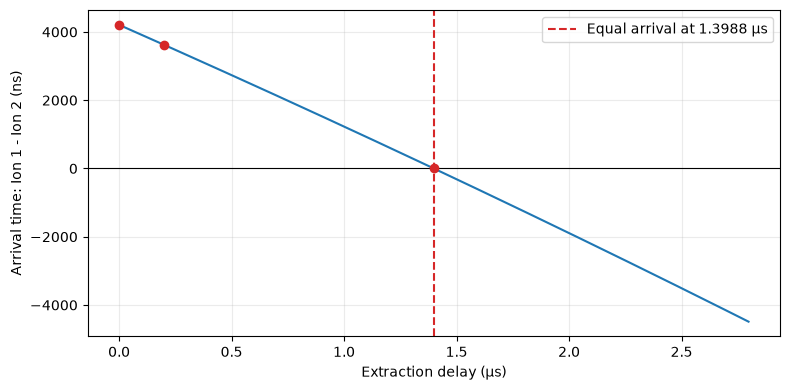

In [32]:
def tof_time_difference(delay_us):
    # Use microseconds for the solver input; return the difference in seconds.
    arrival_1, arrival_2 = tof_trajectory(tof_initial_speeds, delay_us * 1e-6)[3]
    return float(arrival_1 - arrival_2)


tof_max_delay_us = tof_gap / tof_initial_speeds.max() * 1e6
tof_bracket_us = (0.0, 0.99 * tof_max_delay_us)
assert tof_time_difference(tof_bracket_us[0]) * tof_time_difference(tof_bracket_us[1]) < 0

tof_optimal_delay_us = brentq(
    tof_time_difference, *tof_bracket_us, xtol=1e-12, rtol=1e-14,
)
tof_optimal_delay_s = tof_optimal_delay_us * 1e-6
tof_optimal_difference = tof_time_difference(tof_optimal_delay_us)
tof_optimal = tof_table(tof_optimal_delay_s)

print(f'Optimal extraction delay: {tof_optimal_delay_us * 1000:.6f} ns')
show_tof_table(tof_optimal)
print(f'Unrounded arrival difference: {tof_optimal_difference:.3e} s')
assert abs(tof_optimal_difference) < 1e-12, 'Arrival times must agree within 1 ps.'

# Verify that both ions remain in the gap and traverse it consistently.
remaining = tof_gap - tof_initial_speeds * tof_optimal_delay_s
accel_times = tof_optimal['Acceleration time (µs)'].to_numpy() * 1e-6
assert np.all(remaining > 0)
assert np.allclose(
    tof_initial_speeds * accel_times + 0.5 * tof_acceleration * accel_times**2,
    remaining, rtol=1e-12, atol=0.0,
)

tof_delay_curve_us = np.linspace(0, 2 * tof_optimal_delay_us, 300)
tof_difference_curve_ns = np.array([
    tof_time_difference(delay) for delay in tof_delay_curve_us
]) * 1e9
tof_marker_delays = np.array([0.0, tof_delay_200ns * 1e6, tof_optimal_delay_us])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tof_delay_curve_us, tof_difference_curve_ns)
ax.axhline(0, color='black', linewidth=0.8)
ax.scatter(
    tof_marker_delays,
    [tof_time_difference(delay) * 1e9 for delay in tof_marker_delays],
    color='tab:red', zorder=3,
)
ax.axvline(tof_optimal_delay_us, color='tab:red', linestyle='--',
           label=f'Equal arrival at {tof_optimal_delay_us:.4f} µs')
ax.set_xlabel('Extraction delay (µs)')
ax.set_ylabel('Arrival time: Ion 1 - Ion 2 (ns)')
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

### Problem 2 answers and interpretation

For an initially stationary +1 antibody ion, the final speed is **1,614.841 m/s** and the 1 m drift time is **619.255987 microseconds**. Including the 1 cm acceleration region gives an arrival time of **631.641107 microseconds** from the laser pulse.

For the two ions with initial velocities of 100 and 200 m/s, respectively:

| Extraction delay | Ion 1 final velocity (m/s) | Ion 2 final velocity (m/s) | Ion 1 arrival (microseconds) | Ion 2 arrival (microseconds) | Arrival difference (microseconds) |
| --- | ---: | ---: | ---: | ---: | ---: |
| 0 ns | 1,617.934 | 1,627.179 | 629.713924 | 625.506351 | 4.207573 |
| 200 ns | 1,616.322 | 1,623.971 | 630.518189 | 626.895885 | 3.622304 |
| 1,398.825374 ns | 1,606.622 | 1,604.605 | 635.377884 | 635.377884 | 0 to numerical precision |

Arrival times include the delay, acceleration, and drift. Use the unrounded solver result in cell 2.4 for the equality check; the arrival-time difference is below 1 ps.

The optimal delay lets the initially faster ion move farther toward the extraction-region exit. It then receives less acceleration energy and exits **slightly slower** than Ion 1. Ion 2 spends less time in the acceleration region but more time in the drift tube; at the solved delay these differences cancel. Only the delay changes: the 2 kV voltage, geometry, mass, charge, and initial velocities remain fixed.

Equal final velocities would equalize only the drift times, leaving unequal acceleration times. Including both stages is therefore essential to minimize the full detector arrival-time difference.

## Problem 3 — Antibody motion and vacuum requirements in FTICR

**Prompt:** A 148 kDa antibody ion with charge state +22 is analyzed in a 21 T FTICR. Calculate its frequency, the distance traveled at a 2 cm excitation radius over a 500 ms acquisition, and the pressure needed for the average ion to complete this journey without colliding with background gas.

### 3.1 — Cyclotron frequency

For ideal circular cyclotron motion, the magnetic force supplies the centripetal force:

$$\frac{mv^2}{r}=zevB,\qquad \omega_c=\frac{v}{r}=\frac{zeB}{m},\qquad f_c=\frac{zeB}{2\pi m}.$$

Use $m=148{,}000$ Da, $z=22$, and $B=21$ T. Treat the quoted 148 kDa as the ion mass at the precision given; adding the proton masses would make only a small correction. This is the ideal cyclotron frequency, neglecting trapping-field shifts and ion interactions. It is independent of excitation radius.

**Sources:** *Mass Analyzer Equations*, p. 3 (FTICR and mean free path); *Ion Motion and Mass Analyzers* handout, Sections 3–4; and *Ion Motion Class Notes*, pp. 6–8. For the pressure estimate, use the lecture mean-free-path equation and its nitrogen cross section, with an assumed temperature of 298 K.

In [33]:
icr_mass = 148000.0 * u  # kg
icr_charge_state = 22
icr_B = 21.0            # T
icr_radius = 0.020       # m
icr_acquisition = 0.500  # s

icr_omega = icr_charge_state * e * icr_B / icr_mass
icr_frequency = icr_omega / (2 * np.pi)
print(f'Ideal cyclotron frequency: {icr_frequency:,.3f} Hz ({icr_frequency / 1000:.6f} kHz)')

Ideal cyclotron frequency: 47,935.988 Hz (47.935988 kHz)


### 3.2 — Distance traveled during 500 ms

Each orbit has circumference $2\pi r$. The number of revolutions and total path length are

$$N=f_ct_{\mathrm{acq}},\qquad v=2\pi r f_c=\omega_c r,\qquad
S=(2\pi r)N=v t_{\mathrm{acq}}.$$

Use the full circular path length, rather than the net displacement or the 4 cm orbit diameter. Assume the 2 cm radius remains constant throughout acquisition and ignore any additional axial motion.

In [34]:
icr_revolutions = icr_frequency * icr_acquisition
icr_speed = icr_omega * icr_radius
icr_distance = icr_speed * icr_acquisition

print(f'Revolutions in 500 ms: {icr_revolutions:,.3f}')
print(f'Tangential velocity: {icr_speed:,.3f} m/s')
print(f'Total distance traveled: {icr_distance:,.3f} m ({icr_distance / 1000:.6f} km)')

# Check path length and magnetic-force balance with relative tolerances.
assert np.isclose(
    icr_distance, 2 * np.pi * icr_radius * icr_revolutions,
    rtol=1e-12, atol=0.0,
)
assert np.isclose(
    icr_mass * icr_speed**2 / icr_radius,
    icr_charge_state * e * icr_speed * icr_B,
    rtol=1e-12, atol=0.0,
)

Revolutions in 500 ms: 23,967.994
Tangential velocity: 6,023.814 m/s
Total distance traveled: 3,011.907 m (3.011907 km)


### 3.3 — Pressure required for the mean free path

Set the mean free path equal to the distance traveled, $\lambda=3{,}011.907$ m. Using the lecture equation with $T=298$ K and $\sigma=0.43$ nm²:

$$\lambda=\frac{k_BT}{\sqrt{2}\,p\,\sigma}
\quad\Rightarrow\quad
p=\frac{k_BT}{\sqrt{2}\,\sigma\lambda}.$$

Substitute $k_B=1.380649\times10^{-23}$ J/K and $\sigma=4.3\times10^{-19}$ m²:

$$p=\frac{(1.380649\times10^{-23})(298)}
{\sqrt{2}(4.3\times10^{-19})(3{,}011.907)}
=2.246\times10^{-6}\ \mathrm{Pa}
=1.685\times10^{-8}\ \mathrm{Torr}.$$

Thus, the required pressure is **at or below $2.246\times10^{-6}$ Pa ($1.685\times10^{-8}$ Torr)**.

In [35]:
icr_gas_temperature = 298.0       # K
icr_sigma_lecture = 0.43e-18       # m^2
icr_pressure_mean = Boltzmann * icr_gas_temperature / (
    np.sqrt(2) * icr_sigma_lecture * icr_distance
)
print(f'Required pressure: <= {icr_pressure_mean:.6e} Pa')
print(f'Required pressure: <= {icr_pressure_mean / torr:.6e} Torr')


Required pressure: <= 2.246335e-06 Pa
Required pressure: <= 1.684890e-08 Torr


### Problem 3 answers

- **Cyclotron frequency:** 47.936 kHz.
- **Distance traveled in 500 ms at a 2 cm radius:** 3,011.907 m (3.012 km).
- **Pressure for a mean free path of at least that distance:** at or below $2.246\times10^{-6}$ Pa ($1.685\times10^{-8}$ Torr), using $T=298$ K and the lecture cross section of 0.43 nm².